In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Customer Churn / Sales Trend Analysis")
print("Project setup successful!")

Customer Churn / Sales Trend Analysis
Project setup successful!


In [3]:
import os

print("Files inside /content:")
print(os.listdir("/content"))

Files inside /content:
['.config', 'sample_data']


In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if "online retail" in file.lower():
            print(os.path.join(root, file))

/content/drive/MyDrive/Online Retail.xlsx


In [6]:
import pandas as pd

file_path = "/content/drive/MyDrive/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("✅ Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

✅ Dataset loaded successfully!
Number of rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:

# Step 4: Data Cleaning

import pandas as pd
import numpy as np

print("Original dataset rows:", len(df))

# Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Remove rows without CustomerID or InvoiceDate
df = df.dropna(subset=["CustomerID", "InvoiceDate"]).copy()

# Remove cancelled invoices
df = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Keep only positive quantities and prices
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Remove rows without product descriptions
df = df.dropna(subset=["Description"]).copy()

# Convert date to datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

# Remove invalid dates
df = df.dropna(subset=["InvoiceDate"]).copy()

print("\nCleaned dataset rows:", len(df))
print("Remaining missing CustomerIDs:", df["CustomerID"].isnull().sum())
print("\nData cleaning completed successfully!")


Original dataset rows: 541909

Missing values before cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Cleaned dataset rows: 397884
Remaining missing CustomerIDs: 0

Data cleaning completed successfully!


In [8]:

# STEP 5: FEATURE ENGINEERING

# Calculate revenue
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Extract date features
df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["MonthYear"] = df["InvoiceDate"].dt.to_period("M").astype(str)
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()
df["InvoiceHour"] = df["InvoiceDate"].dt.hour

print("Feature engineering completed successfully!")

display(
    df[[
        "InvoiceNo",
        "CustomerID",
        "InvoiceDate",
        "Quantity",
        "UnitPrice",
        "Revenue",
        "Year",
        "MonthYear",
        "DayOfWeek"
    ]].head()
)


Feature engineering completed successfully!


,InvoiceNo,CustomerID,InvoiceDate,Quantity,UnitPrice,Revenue,Year,MonthYear,DayOfWeek
0,536365,17850.0,2010-12-01 08:26:00,6,2.55,15.30,2010,2010-12,Wednesday
1,536365,17850.0,2010-12-01 08:26:00,6,3.39,20.34,2010,2010-12,Wednesday
2,536365,17850.0,2010-12-01 08:26:00,8,2.75,22.00,2010,2010-12,Wednesday
3,536365,17850.0,2010-12-01 08:26:00,6,3.39,20.34,2010,2010-12,Wednesday
4,536365,17850.0,2010-12-01 08:26:00,6,3.39,20.34,2010,2010-12,Wednesday


In [9]:

# STEP 6: BUSINESS KPIs

total_revenue = df["Revenue"].sum()
total_orders = df["InvoiceNo"].nunique()
total_customers = df["CustomerID"].nunique()
total_products = df["StockCode"].nunique()

average_order_value = total_revenue / total_orders

print("===== SALES PERFORMANCE =====")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")


===== SALES PERFORMANCE =====
Total Revenue: £8,911,407.90
Total Orders: 18,532
Total Customers: 4,338
Unique Products: 3,665
Average Order Value: £480.87


,MonthYear,Revenue,Orders
0,2010-12,572713.890,1400
1,2011-01,569445.040,987
2,2011-02,447137.350,997
3,2011-03,595500.760,1321
4,2011-04,469200.361,1149
5,2011-05,678594.560,1555
6,2011-06,661213.690,1393
7,2011-07,600091.011,1331
8,2011-08,645343.900,1280
9,2011-09,952838.382,1755


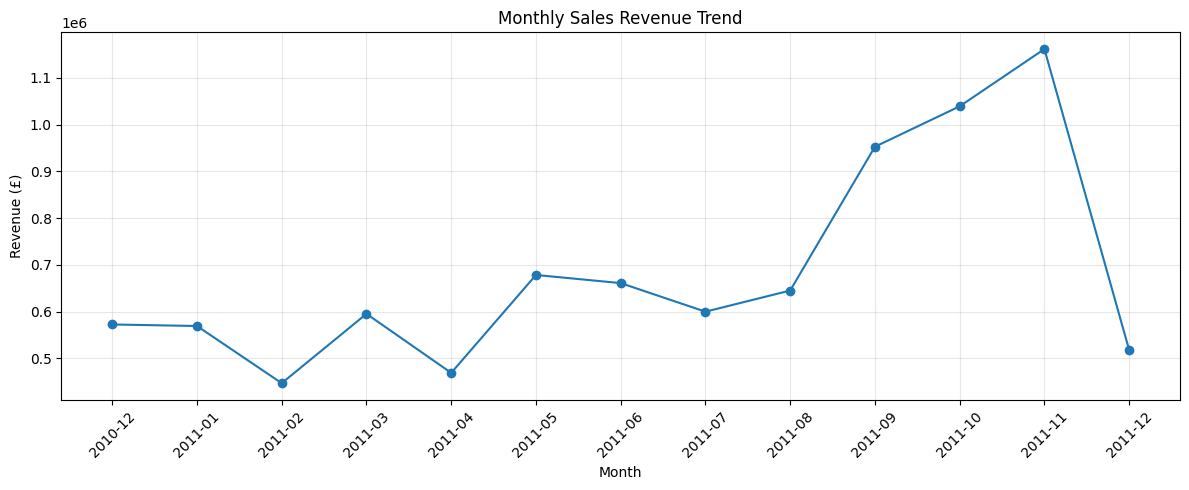

In [10]:

# STEP 7: MONTHLY SALES TREND

import matplotlib.pyplot as plt

monthly_sales = (
    df.groupby("MonthYear")
      .agg(
          Revenue=("Revenue", "sum"),
          Orders=("InvoiceNo", "nunique")
      )
      .reset_index()
      .sort_values("MonthYear")
)

display(monthly_sales)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["MonthYear"],
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:

# STEP 8.1: MONTHLY SALES PIVOT TABLE

monthly_pivot = pd.pivot_table(
    df,
    index="Year",
    columns="Month",
    values="Revenue",
    aggfunc="sum",
    fill_value=0
)

print("Monthly Revenue Pivot Table")
display(monthly_pivot.round(2))


Monthly Revenue Pivot Table


Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2010,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,572713.89
2011,569445.04,447137.35,595500.76,469200.36,678594.56,661213.69,600091.01,645343.9,952838.38,1039318.79,1161817.38,518192.79


In [12]:

# STEP 8.2: COUNTRY-WISE SALES

country_sales = (
    df.groupby("Country")
      .agg(
          Revenue=("Revenue", "sum"),
          Orders=("InvoiceNo", "nunique"),
          Customers=("CustomerID", "nunique")
      )
      .sort_values("Revenue", ascending=False)
)

print("Top 10 Countries by Revenue")
display(country_sales.head(10).round(2))


Top 10 Countries by Revenue


,Revenue,Orders,Customers
Country,,,
United Kingdom,7308391.55,16646,3920
Netherlands,285446.34,94,9
EIRE,265545.90,260,3
Germany,228867.14,457,94
France,209024.05,389,87
Australia,138521.31,57,9
Spain,61577.11,90,30
Switzerland,56443.95,51,21
Belgium,41196.34,98,25


In [13]:
# STEP 9: TOP CUSTOMERS

customer_sales = (
    df.groupby("CustomerID")
      .agg(
          TotalRevenue=("Revenue", "sum"),
          TotalOrders=("InvoiceNo", "nunique"),
          LastPurchase=("InvoiceDate", "max")
      )
      .sort_values("TotalRevenue", ascending=False)
)

print("Top 10 Customers")
display(customer_sales.head(10).round(2))

Top 10 Customers


,TotalRevenue,TotalOrders,LastPurchase
CustomerID,,,
14646.0,280206.02,73,2011-12-08 12:12:00
18102.0,259657.30,60,2011-12-09 11:50:00
17450.0,194550.79,46,2011-12-01 13:29:00
16446.0,168472.50,2,2011-12-09 09:15:00
14911.0,143825.06,201,2011-12-08 15:54:00
12415.0,124914.53,21,2011-11-15 14:22:00
14156.0,117379.63,55,2011-11-30 10:54:00
17511.0,91062.38,31,2011-12-07 10:12:00
16029.0,81024.84,63,2011-11-01 10:27:00


In [14]:
# STEP 10: CUSTOMER SEGMENTATION

reference_date = df["InvoiceDate"].max()

customer_summary = (
    df.groupby("CustomerID")
      .agg(
          TotalRevenue=("Revenue", "sum"),
          TotalOrders=("InvoiceNo", "nunique"),
          LastPurchase=("InvoiceDate", "max")
      )
      .copy()
)

customer_summary["DaysSinceLastPurchase"] = (
    reference_date - customer_summary["LastPurchase"]
).dt.days

def classify_customer(row):
    if row["DaysSinceLastPurchase"] > 90:
        return "Potentially Inactive"
    elif row["TotalOrders"] >= 5:
        return "Loyal Customer"
    else:
        return "Active / Occasional"

customer_summary["Segment"] = customer_summary.apply(
    classify_customer, axis=1
)

print("Customer Segment Counts:")
print(customer_summary["Segment"].value_counts())

display(customer_summary.head(10))

Customer Segment Counts:
Segment
Active / Occasional     1850
Potentially Inactive    1445
Loyal Customer          1043
Name: count, dtype: int64


,TotalRevenue,TotalOrders,LastPurchase,DaysSinceLastPurchase,Segment
CustomerID,,,,,
12346.0,77183.60,1,2011-01-18 10:01:00,325,Potentially Inactive
12347.0,4310.00,7,2011-12-07 15:52:00,1,Loyal Customer
12348.0,1797.24,4,2011-09-25 13:13:00,74,Active / Occasional
12349.0,1757.55,1,2011-11-21 09:51:00,18,Active / Occasional
12350.0,334.40,1,2011-02-02 16:01:00,309,Potentially Inactive
12352.0,2506.04,8,2011-11-03 14:37:00,35,Loyal Customer
12353.0,89.00,1,2011-05-19 17:47:00,203,Potentially Inactive
12354.0,1079.40,1,2011-04-21 13:11:00,231,Potentially Inactive
12355.0,459.40,1,2011-05-09 13:49:00,213,Potentially Inactive


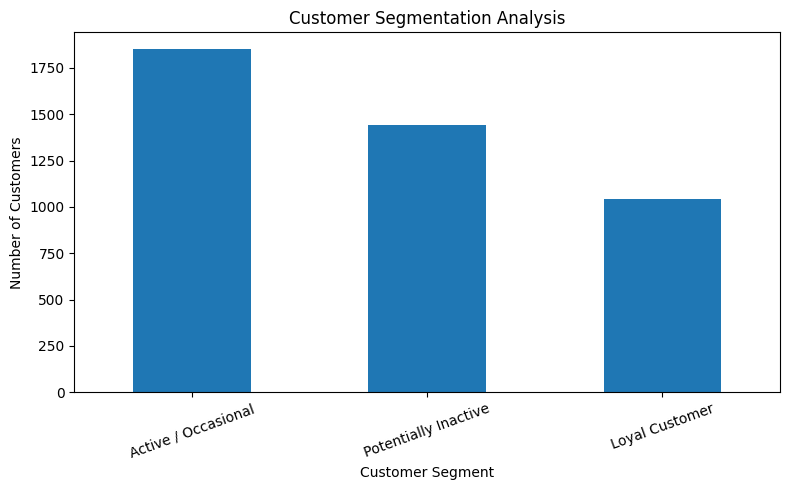

In [15]:
# STEP 11: SEGMENT VISUALIZATION

segment_counts = customer_summary["Segment"].value_counts()

segment_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Customer Segmentation Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [16]:
# STEP 12: BUSINESS RECOMMENDATIONS

best_month = monthly_sales.loc[
    monthly_sales["Revenue"].idxmax()
]

best_country = country_sales["Revenue"].idxmax()

top_customer_id = customer_sales["TotalRevenue"].idxmax()

inactive_count = (
    customer_summary["Segment"] == "Potentially Inactive"
).sum()

print("===== BUSINESS RECOMMENDATIONS =====")

print(
    f"Highest revenue month: {best_month['MonthYear']}"
)

print(f"Top revenue country: {best_country}")

print(f"Highest spending customer ID: {top_customer_id}")

print(f"Potentially inactive customers: {inactive_count}")

print("\nSuggested Actions:")
print("1. Plan promotions during low-sales months.")
print("2. Reward high-value customers with loyalty offers.")
print("3. Send re-engagement offers to potentially inactive customers.")
print("4. Monitor monthly revenue and order trends.")
print("5. Investigate high-performing products and markets.")

===== BUSINESS RECOMMENDATIONS =====
Highest revenue month: 2011-11
Top revenue country: United Kingdom
Highest spending customer ID: 14646.0
Potentially inactive customers: 1445

Suggested Actions:
1. Plan promotions during low-sales months.
2. Reward high-value customers with loyalty offers.
3. Send re-engagement offers to potentially inactive customers.
4. Monitor monthly revenue and order trends.
5. Investigate high-performing products and markets.


In [17]:
# STEP 13: EXPORT FINAL REPORT

output_file = (
    "/content/drive/MyDrive/"
    "Customer_Sales_Analysis_Results.xlsx"
)

with pd.ExcelWriter(output_file) as writer:
    monthly_sales.to_excel(
        writer, sheet_name="Monthly Sales", index=False
    )

    monthly_pivot.to_excel(
        writer, sheet_name="Monthly Pivot"
    )

    country_sales.to_excel(
        writer, sheet_name="Country Analysis"
    )

    customer_sales.to_excel(
        writer, sheet_name="Top Customers"
    )

    customer_summary.to_excel(
        writer, sheet_name="Customer Segments"
    )

print("Excel report saved successfully!")
print("Location:", output_file)

Excel report saved successfully!
Location: /content/drive/MyDrive/Customer_Sales_Analysis_Results.xlsx
